In [10]:
!pip install colour-science

## 基本設定とガンマ補正の定義

In [12]:
import cv2
import numpy as np
import colour

MODELS = ('affine_baseline', 'linear3', 'root_polynomial2')
RIDGE = 1e-3

class ColorCalibration:
    def __init__(self, matrix, bbox, before, after, metadata):
        self.matrix = matrix
        self.bbox = bbox
        self.mean_delta_e00_before = before
        self.mean_delta_e00_after = after
        self.metadata = metadata

def _decode(rgb):
    return np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4)

def _encode(rgb):
    rgb = np.clip(rgb, 0, 1)
    return np.where(rgb <= .0031308, rgb * 12.92, 1.055 * rgb ** (1 / 2.4) - .055)

def reference_colors(name='ColorChecker 2005'):
    if name not in colour.CCS_COLOURCHECKERS:
        raise ValueError(f'Unknown colour-science reference dataset: {name}')
    checker = colour.CCS_COLOURCHECKERS[name]
    if len(checker.data) != 24:
        raise ValueError('Reference must describe a 24-patch ColorChecker')
    xyz = colour.xyY_to_XYZ(np.array(list(checker.data.values())))
    linear = colour.XYZ_to_RGB(xyz, 'sRGB', illuminant=checker.illuminant, chromatic_adaptation_transform='Bradford')
    return _encode(linear), list(checker.data)

def _lab(rgb):
    return colour.XYZ_to_Lab(colour.sRGB_to_XYZ(rgb), illuminant=colour.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65'])


## 色変換数理モデルの定義

In [13]:
def features(rgb, model):
    rgb = np.asarray(rgb, dtype=float)
    if model == 'affine_baseline':
        return np.concatenate([rgb, np.ones(rgb.shape[:-1]+(1,))], axis=-1)
    if model == 'linear3':
        return rgb
    if model == 'root_polynomial2':
        r, g, b = np.moveaxis(np.maximum(rgb, 0), -1, 0)
        return np.stack([r, g, b, np.sqrt(r*g), np.sqrt(r*b), np.sqrt(g*b)], axis=-1)
    raise ValueError(f'Unknown colour model: {model}')

def fit_model(observed_linear, reference_linear, model):
    X = features(observed_linear, model)
    if model == 'affine_baseline':
        return np.linalg.lstsq(X, reference_linear, rcond=None)[0]
    prior = np.zeros((X.shape[1], 3))
    prior[:3] = np.eye(3)
    penalty = RIDGE*np.trace(X.T@X)/X.shape[1]
    return np.linalg.solve(X.T@X+penalty*np.eye(X.shape[1]),
                           X.T@reference_linear+penalty*prior)

def transform_linear(rgb, coefficients, model):
    return features(rgb, model)@coefficients


## チャートグリッド自動検出の定義

In [14]:
def _chart_grid(image):
    """Find repeated square patches, fit their 6x4 grid in image coordinates."""
    scale = min(1., 1400 / max(image.shape[:2]))
    small = cv2.resize(image, None, fx=scale, fy=scale)
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), 30, 90)
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        x, y, w, h = cv2.boundingRect(contour)
        poly = cv2.approxPolyDP(contour, .04 * cv2.arcLength(contour, True), True)
        if 150 < area < small.size * .003 and len(poly) == 4 and .65 < w / h < 1.5 and area / (w * h) > .65:
            center = np.array([x + w / 2, y + h / 2])
            if not any(np.linalg.norm(center - p[:2]) < min(w, h) * .25 for p in candidates):
                candidates.append(np.r_[center, (w + h) / 2])
    candidates = np.array(candidates)
    if len(candidates) < 18:
        raise ValueError('ColorChecker: fewer than 18 square-patch candidates')

    remaining = set(range(len(candidates)))
    groups = []
    while remaining:
        group, stack = [], [remaining.pop()]
        while stack:
            i = stack.pop()
            group.append(i)
            neighbours = [j for j in remaining if .65 < candidates[j, 2] / candidates[i, 2] < 1.5
                          and np.linalg.norm(candidates[j, :2] - candidates[i, :2]) < 1.85 * candidates[i, 2]]
            for j in neighbours:
                remaining.remove(j)
            stack.extend(neighbours)
        if len(group) >= 18:
            groups.append(group)

    for group in sorted(groups, key=len, reverse=True):
        points = candidates[group, :2]
        _, _, axes = np.linalg.svd(points - points.mean(0), full_matrices=False)
        if axes[0, 0] < 0:
            axes[0] *= -1
        if np.linalg.det(axes) < 0:
            axes[1] *= -1
        projected = points @ axes.T
        bins = []
        for dimension, count in enumerate((6, 4)):
            values = projected[:, dimension].astype(np.float32).reshape(-1, 1)
            centers = np.linspace(values.min(), values.max(), count)
            for _ in range(20):
                labels = np.argmin(abs(values - centers), axis=1)
                centers = np.array([values[labels == k].mean() if np.any(labels == k) else centers[k] for k in range(count)])
            bins.append(np.argmin(abs(values - np.sort(centers)), axis=1))
        lattice = np.column_stack(bins).astype(np.float32)
        if len(np.unique(lattice, axis=0)) < 18:
            continue
        transform, inliers = cv2.findHomography(lattice, points.astype(np.float32), cv2.RANSAC, 4.)
        if transform is None or inliers.sum() < 18:
            continue
        grid = np.array([[x, y] for y in range(4) for x in range(6)], np.float32)
        grid = cv2.perspectiveTransform(grid[None], transform)[0] / scale
        return grid.reshape(4, 6, 2), float(np.median(candidates[group, 2]) / scale), int(inliers.sum())
    raise ValueError('ColorChecker: no consistent 6x4 square-patch grid')


## カラーキャリブレーション実行の定義

In [15]:
def calibrate_color(image_bgr, reference_name='ColorChecker 2005', model='affine_baseline'):
    grid, size, inliers = _chart_grid(image_bgr)
    radius = max(2, int(size * .24))
    samples = []
    sampling_clipping = []
    for x, y in grid.reshape(-1, 2):
        x, y = int(round(x)), int(round(y))
        patch = image_bgr[max(0, y-radius):y+radius+1, max(0, x-radius):x+radius+1]
        if not patch.size:
            raise ValueError('ColorChecker sampling outside image')
        samples.append(np.median(patch.reshape(-1, 3), axis=0)[::-1] / 255.)
        sampling_clipping.append(float(np.mean(np.any((patch <= 1) | (patch >= 254), axis=2))))
    samples = np.array(samples).reshape(4, 6, 3)
    reference, names = reference_colors(reference_name)
    reference_lab = _lab(reference)
    options = [(samples, grid, 'identity'), (samples[::-1, ::-1], grid[::-1, ::-1], '180'),
               (samples[:, ::-1], grid[:, ::-1], 'horizontal_flip'), (samples[::-1], grid[::-1], 'vertical_flip')]
    ranked = [(np.mean(colour.delta_E(_lab(s.reshape(24, 3)), reference_lab, method='CIE 2000')), s, g, orientation)
              for s, g, orientation in options]
    before, samples, grid, orientation = min(ranked, key=lambda item: item[0])
    samples = samples.reshape(24, 3)
    observed_linear = _decode(samples)
    reference_linear = _decode(reference)
    matrix = fit_model(observed_linear, reference_linear, model)
    corrected = _encode(transform_linear(observed_linear, matrix, model))
    after_values = colour.delta_E(_lab(corrected), reference_lab, method='CIE 2000')
    after = float(np.mean(after_values))
    if before > 35 or after > 20:
        raise ValueError(f'ColorChecker correspondence QC failed: before={before:.2f}, after={after:.2f}')
    flat = grid.reshape(-1, 2)
    lo = np.floor(flat.min(0) - size * .6).astype(int)
    hi = np.ceil(flat.max(0) + size * .6).astype(int)
    bbox = (int(lo[0]), int(lo[1]), int(hi[0]-lo[0]), int(hi[1]-lo[1]))
    heldout_rgb = []
    for index in range(24):
        keep = np.arange(24) != index
        heldout_matrix = fit_model(observed_linear[keep], reference_linear[keep], model)
        heldout_rgb.append(_encode(transform_linear(observed_linear[index], heldout_matrix, model)))
    heldout_errors = colour.delta_E(_lab(np.array(heldout_rgb)), reference_lab, method='CIE 2000')
    metadata = dict(reference=f'colour-science / {reference_name} xyY', reference_whitepoint='D50',
                    reference_dataset=reference_name, physical_chart_reference_match_confirmed=False,
                    reference_version_note='Chart production date/reference version has not been confirmed. '
                    'Manufacturer changed ColorChecker colorants in November 2014.',
                    reference_version_source='https://xrite.com'
                    'new_color_specifications_for_colorchecker_sg_and_classic_charts',
                    model=model, ridge_strength=RIDGE if model != 'affine_baseline' else 0.,
                    global_transform=True, position_dependent=False,
                    original_rgb_ratios_preserved=False,
                    leave_one_patch_out_mean_delta_e00=float(np.mean(heldout_errors)),
                    leave_one_patch_out_note='Each patch predicted by fitting the other 23 patches; '
                    'reference-based diagnostic, not independent scene-color accuracy.',
                    sampled_patch_clipped_pixel_fraction_max=float(max(sampling_clipping)),
                    adaptation='Bradford D50 to D65', output_space='sRGB / CIELAB D65, 2-degree observer',
                    transform=f'{model} in linear sRGB, {matrix.shape[0]}x3 matrix, output clipped to gamut',
                    feature_terms=(['R', 'G', 'B', 'sqrt(RG)', 'sqrt(RB)', 'sqrt(GB)']
                                   if model == 'root_polynomial2' else None),
                    orientation=orientation, patch_centers=flat.tolist(), patch_size=size,
                    sample_radius_px=radius, geometry_inliers=inliers, patch_names=names,
                    observed_rgb=samples.tolist(), reference_rgb=reference.tolist(),
                    patch_delta_e00_after=after_values.tolist(),
                    qc_note='Training-patch residual; no independent chart/measurement GT; chart aging, glare and spatial illumination are not modeled')
    return ColorCalibration(matrix, bbox, float(before), after, metadata)


## 全画素色補正（CPU/GPU選択）と視覚化オーバーレイの定義

In [16]:
def apply_color_calibration_exact(image_bgr, calibration):
    """Reference CPU implementation of the fitted colour transform."""
    result = np.empty_like(image_bgr)
    matrix = calibration.matrix
    model = calibration.metadata.get('model', 'affine_baseline')
    for start in range(0, image_bgr.shape[0], 128):
        rgb = image_bgr[start:start+128, :, ::-1].astype(float) / 255
        corrected = _encode(transform_linear(_decode(rgb), matrix, model))
        result[start:start+128] = np.rint(corrected[:, :, ::-1] * 255).astype(np.uint8)
    return result

def _apply_color_calibration_gpu(image_bgr, calibration):
    """Exact fitted transform on the available Torch GPU."""
    import torch

    if not torch.cuda.is_available():
        raise RuntimeError('Torch GPU is not available')
    model = calibration.metadata.get('model', 'affine_baseline')
    if model != 'root_polynomial2':
        raise RuntimeError(f'GPU fast path is not implemented for model={model}')

    matrix = torch.as_tensor(
        np.asarray(calibration.matrix, dtype=np.float32),
        device='cuda', dtype=torch.float32)
    rgb = np.ascontiguousarray(image_bgr[:, :, ::-1])
    x = torch.from_numpy(rgb).to(device='cuda', dtype=torch.float32).div_(255.0)
    x = torch.where(x <= .04045, x / 12.92,
                    torch.pow((x + .055) / 1.055, 2.4))
    r, g, b = x.unbind(-1)
    corrected = (
        r[..., None] * matrix[0] +
        g[..., None] * matrix[1] +
        b[..., None] * matrix[2] +
        torch.sqrt(torch.clamp(r * g, min=0))[..., None] * matrix[3] +
        torch.sqrt(torch.clamp(r * b, min=0))[..., None] * matrix[4] +
        torch.sqrt(torch.clamp(g * b, min=0))[..., None] * matrix[5]
    )
    corrected = torch.clamp(corrected, 0, 1)
    corrected = torch.where(
        corrected <= .0031308,
        corrected * 12.92,
        1.055 * torch.pow(corrected, 1 / 2.4) - .055)
    output = torch.round(corrected.mul(255)).clamp_(0, 255).to(torch.uint8)
    output = output.cpu().numpy()[:, :, ::-1]
    return np.ascontiguousarray(output)

def apply_color_calibration(image_bgr, calibration):
    try:
        return _apply_color_calibration_gpu(image_bgr, calibration)
    except Exception:
        return apply_color_calibration_exact(image_bgr, calibration)

def draw_color_overlay(image_bgr, calibration):
    output = image_bgr.copy()
    x, y, w, h = calibration.bbox
    cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 6)
    radius = calibration.metadata['sample_radius_px']
    for index, (x, y) in enumerate(calibration.metadata['patch_centers'], 1):
        x, y = int(x), int(y)
        cv2.rectangle(output, (x-radius, y-radius), (x+radius, y+radius), (0, 255, 0), 3)
        cv2.putText(output, str(index), (x-radius, y-radius-4), cv2.FONT_HERSHEY_SIMPLEX, .9, (0, 0, 255), 2)
    cv2.putText(output, f'DE00 {calibration.mean_delta_e00_before:.2f} -> {calibration.mean_delta_e00_after:.2f}',
                (calibration.bbox[0], calibration.bbox[1]-25), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
    return output


## 背景タイルのサンプリング

In [17]:
def background_tiles(image_bgr, labels, center, radius, *, inner_fraction=.70,
                     seed_margin=11, grid_size=6):
    """Sample equal-weight spatial tiles, excluding rim and expanded seed masks.

    Blue selection is made on the original image, before any colour correction.
    Returned medians are sRGB triplets, plus local tile centers for inspection.
    """
    h, w = labels.shape
    yy, xx = np.ogrid[:h, :w]
    interior = (xx-center[0])**2 + (yy-center[1])**2 < (radius*inner_fraction)**2
    excluded = cv2.dilate((labels > 0).astype(np.uint8),
                          np.ones((seed_margin, seed_margin), np.uint8)) > 0
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    blue = (hsv[..., 0] >= 90) & (hsv[..., 0] <= 135) & (hsv[..., 1] >= 60) & (hsv[..., 2] >= 15)
    valid = interior & ~excluded & blue
    tiles = []
    for row in range(grid_size):
        for col in range(grid_size):
            y0, y1 = row*h//grid_size, (row+1)*h//grid_size
            x0, x1 = col*w//grid_size, (col+1)*w//grid_size
            local = valid[y0:y1, x0:x1]
            if np.count_nonzero(local) < 200:
                continue
            ys, xs = np.nonzero(local)
            tiles.append(dict(x=float(xs.mean()+x0), y=float(ys.mean()+y0),
                              pixels=int(len(xs)),
                              rgb=np.median(image_bgr[y0:y1, x0:x1][local][:, ::-1], axis=0)/255.))
    if len(tiles) < 4:
        raise ValueError('Fewer than four valid background tiles')
    return tiles, valid


## 背景タイルの統計診断・解析

In [18]:
def describe_tiles(rgb):
    rgb = np.asarray(rgb)
    lab = colour.XYZ_to_Lab(colour.sRGB_to_XYZ(rgb))
    representative = np.median(lab, axis=0)
    distances = colour.delta_E(lab, representative, method='CIE 2000')
    xyz = colour.sRGB_to_XYZ(rgb)
    return dict(L=float(representative[0]), a=float(representative[1]),
                b=float(representative[2]), Y=float(np.median(xyz[:, 1])),
                within_dish_tile_delta_e00_p90=float(np.percentile(distances, 90)),
                tile_count=len(rgb))


def between_dishes(rows):
    """Ranges describe observed surfaces, not ground-truth-relative errors."""
    labs = np.array([[r['L'], r['a'], r['b']] for r in rows])
    ys = np.array([r['Y'] for r in rows])
    differences = [float(colour.delta_E(labs[i], labs[j], method='CIE 2000'))
                   for i in range(len(labs)) for j in range(i+1, len(labs))]
    return dict(dish_count=len(rows),
                background_L_range=float(np.ptp(labs[:, 0])),
                background_L_range_percent_of_mean=float(np.ptp(labs[:, 0])/labs[:, 0].mean()*100),
                background_Y_range_percent_of_mean=float(np.ptp(ys)/ys.mean()*100),
                background_pair_delta_e00_max=max(differences, default=0),
                background_pair_delta_e00_mean=float(np.mean(differences)) if differences else 0)


## 画像のアップロードと実行

カラーチャートが写った画像をアップロードしてください:


Saving unnamed.jpg to unnamed (2).jpg


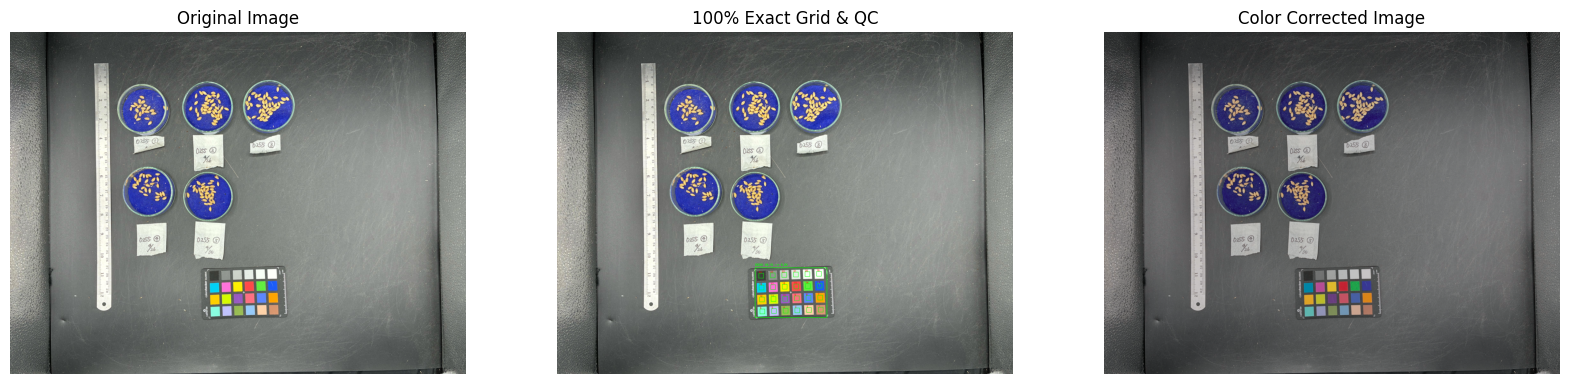

成功！結果画像を 'corrected_result.png' として保存しました。


In [20]:
from google.colab import files
import matplotlib.pyplot as plt

print("カラーチャートが写った画像をアップロードしてください:")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

img = cv2.imread(file_name)

try:
    # 最も高精度な 'root_polynomial2' モデルで計算
    calibration = calibrate_color(img, model='root_polynomial2')
    corrected_img = apply_color_calibration(img, calibration)
    overlay_img = draw_color_overlay(img, calibration)

    # 画面に並べて描画
    fig, axes = plt.subplots(1, 3, figsize=(20, 10))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(cv2.cvtColor(overlay_img, cv2.COLOR_BGR2RGB))
    axes[1].set_title("100% Exact Grid & QC")
    axes[1].axis('off')

    axes[2].imshow(cv2.cvtColor(corrected_img, cv2.COLOR_BGR2RGB))
    axes[2].set_title("Color Corrected Image")
    axes[2].axis('off')

    plt.show()

    cv2.imwrite(f'{file_name}.corrected_result.png', corrected_img)
    print("成功！結果画像を 'corrected_result.png' として保存しました。")

except Exception as e:
    print(f"失敗: {e}")
